# CS781 Phase 5 — Legal Statute Identification
## Data preparation, model checks and timing

This notebook establishes the data and model interfaces before the four LSI training runs. It audits the official splits and label vocabulary, reuses the original legal BPE, creates a resumable packed token cache, and checks the inherited architectures with the multi-label document head.

The planned experiments are decoder partial fine-tuning, encoder–decoder adapters, prefix LoRMA+, and an efficient-derived distilled student. Preparation does not create a trained submission model. The short learning checks use temporary model instances whose parameter changes are discarded.

The target training allowance is 3.5 hours per run, with a 5-hour cap. Timing estimates are measurements from this session; model quality is evaluated in the later training notebook.


### Kaggle inputs

Attach [the preparation source package](CS781_Phase5_Preparation_Package.zip) to Kaggle along with the Phase 1 tokenizer and checkpoints. If Kaggle extracts the package, set `SOURCE_ROOT` to the folder containing `phase5_package.json`.


### Inputs and execution

The source package accompanies this notebook. Original inputs are the prep-2 tokenizer and the four Phase 1 checkpoint datasets. LSI JSON files are downloaded from the official repository at a pinned commit, or read from an attached LSI folder.

A gated download uses the Kaggle secret HF_TOKEN. CPU preparation is available with RUN_GPU_CHECKS=False. The model/timing section uses GPU T4 x2. An attached prepared-data bundle is detected and reused in a later session.

The official evaluate_phase5.py can be attached separately. Its check remains explicitly pending when the file is unavailable.


## 1. Project setup


In [1]:
from pathlib import Path
import hashlib
import json
import shutil
import sys
import zipfile

INPUT_ROOT = Path("/kaggle/input")
PROJECT_ROOT = Path("/kaggle/working/cs781_phase5")
SOURCE_ROOT = None

if SOURCE_ROOT is None:
    markers = list(INPUT_ROOT.rglob("phase5_package.json"))
    local_marker = Path.cwd() / "phase5_package.json"
    if not markers and local_marker.is_file():
        markers = [local_marker]
    if len(markers) == 1:
        SOURCE_ROOT = markers[0].parent
    elif len(markers) > 1:
        raise ValueError("Several source packages found. Set SOURCE_ROOT to one package folder.")
    else:
        archives = list(INPUT_ROOT.rglob("CS781_Phase5_Preparation_Package.zip"))
        if len(archives) != 1:
            raise FileNotFoundError("Attach CS781_Phase5_Preparation_Package.zip as a Kaggle dataset.")
        extracted = PROJECT_ROOT.parent / "phase5_source_input"
        extracted.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archives[0]) as archive:
            for member in archive.infolist():
                target = (extracted / member.filename).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError("Unsafe source-package member.")
            archive.extractall(extracted)
        matches = list(extracted.rglob("phase5_package.json"))
        if len(matches) != 1:
            raise ValueError("The source package needs one phase5_package.json.")
        SOURCE_ROOT = matches[0].parent

SOURCE_ROOT = Path(SOURCE_ROOT)
package = json.loads((SOURCE_ROOT / "phase5_package.json").read_text())
if package["package_id"] != "cs781_phase5_preparation":
    raise ValueError("Unexpected source package.")

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
for relative, expected_hash in package["sha256"].items():
    source = SOURCE_ROOT / relative
    if hashlib.sha256(source.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("Source package changed: " + relative)
    if relative.startswith(("src/", "configs/")) or relative in ("README.md", "SOURCES.md", "local_validation.json"):
        target = PROJECT_ROOT / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        if target.exists() and target.read_bytes() != source.read_bytes():
            raise ValueError("Working source differs. Preserve it and choose a fresh PROJECT_ROOT.")
        if source.resolve() != target.resolve():
            shutil.copy2(source, target)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print("Project:", PROJECT_ROOT)
print("Source version:", package["version"])


Project: /kaggle/working/cs781_phase5
Source version: 1.0.0


## 2. Preparation settings

I keep the initial document budget common across architectures: four 512-position windows, 64 content-token overlap, and uniform coverage. Labels use independent sigmoid outputs. Positive-label weights are damped and capped using training counts.

The timing probe measures a physical batch and accumulated update separately. An out-of-memory retry may reduce the physical batch while preserving the effective case count. The epoch proposal is computed from measured cost, capped at ten, and recorded before training.


In [2]:
CONFIG = json.loads((PROJECT_ROOT / "configs/preparation_defaults.json").read_text())
CONFIG.update(project_root=str(PROJECT_ROOT), input_root=str(INPUT_ROOT))

# Input overrides are only needed when automatic discovery is ambiguous.
LOCAL_LSI_INPUT = None
PREPARED_INPUT = None
TOKENIZER_INPUT = None
LABEL_VOCAB_INPUT = None
EVALUATOR_INPUT = None
CHECKPOINT_INPUTS = {
    "decoder": None,
    "encoder_decoder": None,
    "prefix": None,
    "efficient": None,
}

RUN_GPU_CHECKS = True
STAGE_CHECKPOINTS = True
TARGET_TRAINING_HOURS = 3.5
MAX_RUN_HOURS = 5.0

CONFIG.update(
    local_lsi_input=LOCAL_LSI_INPUT,
    prepared_input=PREPARED_INPUT,
    tokenizer_input=TOKENIZER_INPUT,
    label_vocab_input=LABEL_VOCAB_INPUT,
    evaluator_input=EVALUATOR_INPUT,
    checkpoint_inputs=CHECKPOINT_INPUTS,
    run_gpu_checks=RUN_GPU_CHECKS,
    stage_checkpoints=STAGE_CHECKPOINTS,
    target_training_hours=TARGET_TRAINING_HOURS,
    max_run_hours=MAX_RUN_HOURS,
)

print("Architectures:", ", ".join(CONFIG["architectures"]))
print("Document windows:", CONFIG["max_chunks"], "x", CONFIG["total_tokens"])
print("Training target / cap:", TARGET_TRAINING_HOURS, "/", MAX_RUN_HOURS, "hours")


Architectures: decoder, encoder_decoder, prefix, efficient
Document windows: 4 x 512
Training target / cap: 3.5 / 5.0 hours


In [3]:
import importlib.util
import subprocess
import os

needed = ["numpy", "pandas", "matplotlib"]
if LOCAL_LSI_INPUT is None and PREPARED_INPUT is None:
    cached_here = (PROJECT_ROOT / "prepared/cache/manifest.json").is_file()
    cached_input = any(p.parent.name == "cache" and p.parent.parent.name == "prepared"
                       and "phase5" in str(p).lower() for p in INPUT_ROOT.rglob("manifest.json"))
    if not cached_here and not cached_input:
        needed.append("huggingface_hub")
missing = [name for name in needed if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

if importlib.util.find_spec("torch") is None:
    raise RuntimeError("This notebook uses the PyTorch image supplied by Kaggle.")

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
import pandas as pd
from IPython.display import display, FileLink
from common import write_json, read_json
from lsi_prepare import (
    restore_prepared, prepare_data, prepare_tokens, resolve_checkpoints,
    evaluator_check, run_model_checks, model_summary, export_outputs,
)


## 3. Data and label audit

Statute IDs are mapped to ordered internal columns and restored to their original integers at export. Without an official vocabulary file, the observed train/dev label union is recorded as a provisional schema. The supplied evaluator's reference-derived label dimension remains a separate contract check.

Exact repeated training rows use the same ID, text hash and label set. Development rows retain their supplied multiplicity. Cross-split overlap is measured and reported without silently removing official evaluation examples.


In [4]:
restored = restore_prepared(CONFIG)
documents, data_manifest, data_audit = prepare_data(CONFIG)

display(pd.DataFrame(data_audit["split_statistics"]).T)
print("Data revision:", data_manifest["revision"])
print("Effective training rows:", data_audit["effective_train_rows"])
print("Label columns:", data_audit["label_vocabulary"]["columns"])
print("Labels absent from training:", len(data_audit["labels_without_train_positives"]))
print("Labels absent from development:", len(data_audit["labels_without_dev_positives"]))


LSI rows: {'train': 42750, 'dev': 10181, 'test': 13019}
Effective training rows: 42750 | statute columns: 100
Label schema source: train_dev_observed_union


,rows,unique_original_ids,unique_forward_inputs,same_input_conflicting_label_sets,mean_characters,labels_per_case
train,42750,42750,42750,0,6895.475649,"{'0': 1.0, '50': 3.0, '90': 7.0, '100': 31.0}"
dev,10181,10181,10181,0,7686.018957,"{'0': 1.0, '50': 3.0, '90': 7.0, '100': 28.0}"
test,13019.0,13019.0,13019.0,0.0,7482.083186,NaN


Data revision: 93b0059be756c6c461f3a225de25aabda7d5f84a
Effective training rows: 42750
Label columns: 100
Labels absent from training: 0
Labels absent from development: 0


In [5]:
label_table = pd.read_csv(PROJECT_ROOT / "reports/label_frequencies.csv")
display(label_table.groupby("frequency_group", sort=False).agg(
    statute_count=("statute_id", "count"),
    total_train_positives=("train_positive", "sum"),
))
display(label_table.sort_values("train_positive").head(15))
display(pd.DataFrame(data_audit["cross_split_overlap"]))
display(pd.read_csv(PROJECT_ROOT / "reports/reference_baselines.csv"))


,statute_count,total_train_positives
frequency_group,,
frequent,100,158388


,statute_id,train_positive,dev_positive,positive_weight,initial_logit_bias,frequency_group
84,84,272,68,10.0,-2.746530,frequent
25,25,287,72,10.0,-2.692592,frequent
23,23,304,80,10.0,-2.634744,frequent
66,66,309,78,10.0,-2.618339,frequent
92,92,309,77,10.0,-2.618339,frequent
59,59,310,86,10.0,-2.615089,frequent
50,50,318,80,10.0,-2.589462,frequent
74,74,319,80,10.0,-2.586304,frequent
27,27,329,83,10.0,-2.555249,frequent
15,15,336,84,10.0,-2.534062,frequent


,a,b,shared_original_ids,right_rows_matching_exact_text,right_rows_matching_normalized_text,example_right_row_uids
0,train,dev,0,118,118,"[dev:00000126:62626984, dev:00000202:1426905, ..."
1,train,test,0,150,153,"[test:00000061:181047243, test:00000080:164426..."
2,dev,test,0,95,98,"[test:00000061:181047243, test:00000086:92925,..."


,baseline,macro_f1,micro_f1,macro_precision,macro_recall,subset_accuracy,mean_predicted_labels,label_universe
0,empty_set,0.000000,0.00000,0.000000,0.00,0.000000,0.0,all columns in the saved preparation vocabulary
1,most_frequent_training_label,0.004477,0.11733,0.002884,0.01,0.002848,1.0,all columns in the saved preparation vocabulary


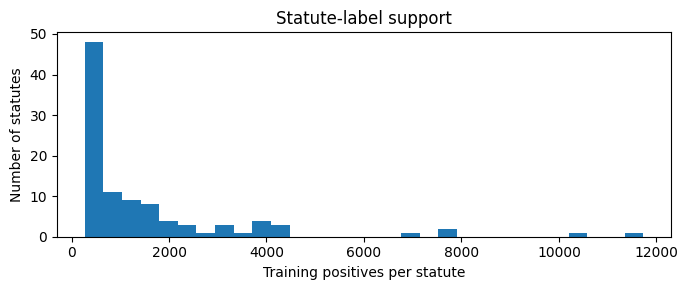

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(label_table["train_positive"], bins=30)
ax.set(xlabel="Training positives per statute", ylabel="Number of statutes",
       title="Statute-label support")
fig.tight_layout()
plt.show()


## 4. Original tokenizer and packed token cache

I reuse the original 16,000-token legal BPE without fitting new merges. The tokenizer state, signature, reserved IDs and round trips are verified.

Tokens are appended to one binary array with a committed row journal. Completed rows survive an interrupted preparation; incomplete writes are truncated at resume. Offset arrays provide case slices without opening one NPZ file per case. The cache contains content tokens, while BOS/EOS and padding are added by the collator.

The coverage table compares window-selection policies; it is not an accuracy ablation.


In [7]:
token_lengths, policy_coverage = prepare_tokens(CONFIG, documents, data_manifest)
display(token_lengths)
display(policy_coverage)

del documents
import gc
gc.collect()


Tokenizing/reusing 0/65,950 rows
Packed 9,656/65,950 | 0.3 min
Packed 20,200/65,950 | 0.7 min
Packed 30,877/65,950 | 1.0 min
Packed 41,262/65,950 | 1.3 min
Packed 50,315/65,950 | 1.7 min
Packed 59,199/65,950 | 2.0 min
Packed 65,950/65,950 | 2.3 min


,split,rows,tokens_p0,tokens_p25,tokens_p50,tokens_p75,tokens_p90,tokens_p95,tokens_p99,tokens_p100
0,train,42750,3.0,491.0,1097.0,3548.75,7145.0,10306.0,21322.59,231377.0
1,dev,10181,4.0,521.0,1392.0,4115.00,7699.0,11130.0,23173.20,192653.0
2,test,13019,3.0,534.0,1376.0,3866.00,7330.8,10534.2,22316.48,379251.0


,split,policy,mean_chunks,mean_content_coverage,total_selected_token_positions
0,train,uniform,2.720889,0.781667,49599328
1,train,head,2.720889,0.788898,53283135
2,train,tail,2.720889,0.767621,49599328
3,train,head_tail,2.720889,0.773490,49599328
4,dev,uniform,2.850997,0.749421,12468076
5,dev,head,2.850997,0.757830,13482171
6,dev,tail,2.850997,0.733406,12468076
7,dev,head_tail,2.850997,0.740048,12468076
8,test,uniform,2.854597,0.758145,15975592
9,test,head,2.854597,0.767313,17266551


0

## 5. Multi-label schema and evaluator check

A document target is a multi-hot vector. Training uses weighted binary cross-entropy on logits, and distillation compares independent Bernoulli probabilities rather than a softmax across statutes.

The internal smoke case validates IDs, integer label sets and local metrics. If an official evaluator is attached, its output is compared on the same full-development baseline. Agreement on this smoke case is reported with its scope; a missing or incompatible evaluator is kept visible.


In [8]:
evaluation_check = evaluator_check(CONFIG)
print("Internal schema:", evaluation_check["internal_schema_check"])
print("Official evaluator:", evaluation_check["official_status"])
display(pd.Series(evaluation_check["internal_metrics"]))

if evaluation_check["official_status"] == "review_needed":
    print(evaluation_check.get("stdout", ""))
    print(evaluation_check.get("stderr", evaluation_check.get("error", "")))
elif evaluation_check["official_status"] == "not_attached":
    print("Official label-dimension agreement remains pending; preparation and timing can continue.")


Internal schema: passed
Official evaluator: passed_smoke_case


macro_f1                                                        0.004477
micro_f1                                                         0.11733
macro_precision                                                 0.002884
macro_recall                                                        0.01
subset_accuracy                                                 0.002848
mean_predicted_labels                                                1.0
label_universe           all columns in the saved preparation vocabulary
dtype: object

## 6. Mathematical checks

These small fixtures check chunk bounds, LoRMA+ identity/matrix equivalence, adapter initialization, the manual BiGRU, multi-hot BCE and Bernoulli distillation. They do not create a trained teacher cache.


In [9]:
from lsi_validation import run_math_checks

mathematical_checks = run_math_checks()
write_json(PROJECT_ROOT / "reports/mathematical_checks.json", mathematical_checks)
display(pd.Series(mathematical_checks["checks"]))


/kaggle/working/cs781_phase5/src/lsi_validation.py:58: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  assert abs(float(same))<1e-6


chunk_bounds_and_full_coverage                          passed
lorma_identity_rectangular_matrix_and_gradients         passed
adapter_identity_initialization                         passed
manual_bigru_matches_reference                          passed
independent_sigmoid_multihot_bce_and_gradients          passed
bernoulli_kd_identity_gradients_and_detached_teacher    passed
dtype: object

## 7. Phase 1 checkpoint identities

The four original checkpoints are located by their run identifiers and checked against the saved Phase 1 SHA-256 references. Optional local staging reads each mounted checkpoint sequentially and leaves future loading on working storage.

Strict tensor loading, tokenizer compatibility and the native readout are checked in the per-architecture probe. Original checkpoints are not added to the preparation output ZIPs.


In [10]:
input_table = resolve_checkpoints(CONFIG)
display(input_table[["architecture", "bytes", "byte_identity", "path"]])


Finding original checkpoint: decoder
Finding original checkpoint: encoder_decoder
Finding original checkpoint: prefix
Finding original checkpoint: efficient


,architecture,bytes,byte_identity,path
0,decoder,871513977,passed,/kaggle/working/cs781_phase5/staged_checkpoint...
1,encoder_decoder,871503069,passed,/kaggle/working/cs781_phase5/staged_checkpoint...
2,prefix,871521847,passed,/kaggle/working/cs781_phase5/staged_checkpoint...
3,efficient,871562425,passed,/kaggle/working/cs781_phase5/staged_checkpoint...


## 8. Architecture and timing probes

Each architecture runs in a separate process. The probe verifies the original readout, real-chunk masks, label-wise attention, intended trainability and two-device output/gradient agreement.

Memory checks use full-size windows. Timing uses representative effective-training rows, a warm-up update, then three measured accumulated updates with zero learning rate. AdamW state is allocated during the check. A short separate learning test verifies that loss can decrease; its weights are discarded.

The efficient probe uses the compact student architecture. Actual KD adds cached teacher logits and a small Bernoulli loss calculation. Teacher-cache generation is a separate cost.


In [11]:
if RUN_GPU_CHECKS:
    timing_summary = run_model_checks(CONFIG)
else:
    timing_summary = model_summary(CONFIG)
    print("Data-only preparation: architecture/GPU probes have not run.")

display(timing_summary)



Model probe: decoder
Loading original Phase 1 checkpoint: decoder
Checking original readout
Checking padding and label-wise attention
Checking two-device execution
Measuring full update groups
Timing update 1/4: 4.04s
Timing update 2/4: 3.94s
Timing update 3/4: 3.77s
Timing update 4/4: 3.83s
Checking temporary learning
Probe result: passed

Model probe: encoder_decoder
Loading original Phase 1 checkpoint: encoder_decoder
Checking original readout
Checking padding and label-wise attention
Checking two-device execution
Measuring full update groups
Timing update 1/4: 11.20s
Timing update 2/4: 10.34s
Timing update 3/4: 10.41s
Timing update 4/4: 10.68s
Checking temporary learning
Probe result: passed

Model probe: prefix
Loading original Phase 1 checkpoint: prefix
Checking original readout
Checking padding and label-wise attention
Checking two-device execution
Measuring full update groups
Timing update 1/4: 29.06s
Timing update 2/4: 26.73s
Timing update 3/4: 26.10s
Timing update 4/4: 27.32

,architecture,status,total_parameters,trainable_parameters,physical_batch,accumulation,seconds_per_update,train_epoch_minutes,full_validation_minutes,epochs_in_target_budget_with_two_validations_per_epoch,scope
0,decoder,passed,218730148,26056356,8,8,3.834318,42.688739,6.065326,3.830761,Extrapolation from representative training row...
1,encoder_decoder,passed,223219492,5437220,8,8,10.409714,115.894821,7.596067,1.601990,Extrapolation from representative training row...
2,prefix,passed,221091492,3229348,8,8,26.730206,297.596296,14.434988,0.643252,Extrapolation from representative training row...
3,efficient,passed,55034788,55034788,8,8,3.307196,36.820117,2.571084,5.004494,Extrapolation from representative training row...


## 9. Budget interpretation

The proposed epoch allowance uses measured update cost and an estimate of two validations per epoch, targeting 3.5 training hours with a 5-hour training cap. Setup, checkpoint writing and teacher-cache export have additional costs.

The proposal is not a trained result. A model estimated to process less than one epoch within the target budget needs review of geometry and throughput before launching its training run. A failed probe is reported independently; it does not invalidate an already completed token cache.


In [12]:
from lsi_prepare import budget_records

proposed_configs = budget_records(CONFIG)
display(pd.DataFrame([
    {
        "architecture": name,
        "epochs": config["epochs"],
        "physical_batch": config["train_batch_cases"],
        "accumulation": config["accumulation_steps"],
        "backbone_lr": config["backbone_lr"],
        "head_lr": config["head_lr"],
        "max_run_hours": config["max_run_hours"],
        "less_than_one_epoch_in_target_budget": config["less_than_one_epoch_in_target_budget"],
    }
    for name, config in proposed_configs.items()
]))


,architecture,epochs,physical_batch,accumulation,backbone_lr,head_lr,max_run_hours,less_than_one_epoch_in_target_budget
0,decoder,3,8,8,0.000005,0.0001,5.0,False
1,encoder_decoder,1,8,8,0.000100,0.0001,5.0,False
2,prefix,1,8,8,0.000100,0.0001,5.0,True
3,efficient,5,8,8,0.000010,0.0001,5.0,False


## 10. Saved artifacts

The prepared-data bundle contains packed tokens, row/label identities and the reports needed to reuse them. The smaller diagnostics bundle contains audits, source snapshots, mathematical checks, probe logs and timing/configuration records.

Both are reusable outputs. Neither is a Codabench prediction archive or a trained model backup.


In [13]:
status = export_outputs(CONFIG)
display(pd.Series({k: v for k, v in status.items() if k != "model_probe_status"}))
display(pd.DataFrame(status["model_probe_status"]))

for name in ("prepared_data_zip", "diagnostics_zip"):
    path = Path(status[name])
    print(path, f"({path.stat().st_size / 2**20:.1f} MiB)")
    display(FileLink(str(path)))


Packing reusable LSI data: /kaggle/working/phase5_lsi_prepared_data.zip
Packing preparation diagnostics: /kaggle/working/phase5_lsi_preparation_diagnostics.zip


data_ready                                                                True
official_evaluator_status                                    passed_smoke_case
submission_count_planned                                                     4
training_started                                                         False
prepared_data_zip                 /kaggle/working/phase5_lsi_prepared_data.zip
diagnostics_zip              /kaggle/working/phase5_lsi_preparation_diagnos...
dtype: object

,architecture,status
0,decoder,passed
1,encoder_decoder,passed
2,prefix,passed
3,efficient,passed


/kaggle/working/phase5_lsi_prepared_data.zip (192.7 MiB)


/kaggle/working/phase5_lsi_prepared_data.zip

/kaggle/working/phase5_lsi_preparation_diagnostics.zip (0.4 MiB)


/kaggle/working/phase5_lsi_preparation_diagnostics.zip

## References

- Course Capstone.pdf, Phase 5 sections 11.1–11.4; official evaluate_phase5.py when supplied.
- Official dataset: https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone . The resolved commit and file hashes are retained.
- Chalkidis et al. (2019), label-wise attention for legal multi-label classification: https://aclanthology.org/P19-1636/ .
- Houlsby et al. (2019), bottleneck adapters: https://proceedings.mlr.press/v97/houlsby19a.html .
- Bihany, Patel and Modi (2025), LoRMA+: https://aclanthology.org/2025.findings-acl.527/ .
- Hinton, Vinyals and Dean (2015), knowledge distillation: https://arxiv.org/abs/1503.02531 .
- PyTorch BCEWithLogitsLoss: https://docs.pytorch.org/docs/2.11/generated/torch.nn.BCEWithLogitsLoss.html .
- Hugging Face revision-pinned downloads: https://huggingface.co/docs/huggingface_hub/guides/download .

Shared native backbones, legal BPE and checked adaptation components are retained from the original Phase 1/4 implementation. New Phase 5 code implements label-wise chunk attention, multi-label targets, Bernoulli distillation, packed preparation and task-specific audits. Additional source notes are in SOURCES.md.
